<a href="https://colab.research.google.com/github/edwardmoreno18/RedesNeuronales_V/blob/main/R2_A1_S10_Redes_Neuronales_V.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Importo math para realizar operaciones matemáticas.
import math

# Importo random para generar valores aleatorios y seleccionar muestras.
import random

# Importo os para gestionar directorios y archivos del sistema.
import os

# Importo itertools para trabajar con iteraciones y combinaciones.
import itertools

# Importo NumPy para trabajar con matrices y arreglos numéricos.
import numpy as np

# Importo Matplotlib para visualizar imágenes, gráficas y resultados.
import matplotlib.pyplot as plt

# Importo Image e ImageDraw de PIL para crear y dibujar imágenes.
from PIL import Image, ImageDraw

# Importo PyTorch, biblioteca utilizada para construir redes neuronales.
import torch

# Importo nn para definir capas y arquitecturas de redes neuronales.
import torch.nn as nn

# Importo las funciones auxiliares de PyTorch.
import torch.nn.functional as F

# Importo Dataset y DataLoader para organizar los datos
# y suministrarlos a la red neuronal durante el entrenamiento.
from torch.utils.data import Dataset, DataLoader


In [ ]:
# Defino una semilla para controlar la generación de números aleatorios.
SEED = 42

# Configuro la semilla de la biblioteca random.
random.seed(SEED)

# Configuro la semilla de NumPy.
np.random.seed(SEED)

# Configuro la semilla de PyTorch.
torch.manual_seed(SEED)

# Verifico si existe una GPU compatible con CUDA.
# Si está disponible, la utilizo; de lo contrario, ejecuto en CPU.
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# Muestro la versión instalada de PyTorch.
print('PyTorch:', torch.__version__)

# Muestro el dispositivo seleccionado para ejecutar el modelo.
print('Dispositivo:', DEVICE)

PyTorch: 2.14.0+cpu
Dispositivo: cpu


In [ ]:
# Defino una función que genera un rostro sintético.
# identity identifica a la persona y variant representa una variación
# de su rostro. size establece el tamaño de la imagen.
def synthetic_face(identity, variant, size=64):

    # Creo un generador aleatorio específico para cada combinación
    # de identidad y variante.
    rng = random.Random(identity * 1000 + variant)

    # Creo una imagen en escala de grises ('L') de 64 x 64 píxeles.
    # El valor 230 establece el color inicial del fondo.
    img = Image.new('L', (size, size), color=230)

    # Creo un objeto de dibujo para agregar los elementos del rostro.
    d = ImageDraw.Draw(img)

    # Defino parámetros diferentes para cada una de las cuatro identidades.
    # Estos valores controlan la separación de los ojos, su posición,
    # el tamaño, la posición de la boca y el estilo del rostro.
    params = [
        (18, 20, 10, 42, 0),
        (16, 22, 12, 40, 1),
        (20, 18, 9, 44, 2),
        (17, 19, 13, 41, 3),
    ][identity]

    # Descompongo los parámetros para utilizarlos individualmente.
    eye_dx, eye_y, eye_r, mouth_y, style = params

    # Introduzco pequeños desplazamientos aleatorios horizontales
    # y verticales para generar variaciones en cada rostro.
    jx = rng.randint(-2, 2)
    jy = rng.randint(-2, 2)

    # Dibujo la forma principal de la cara mediante una elipse.
    # Los desplazamientos permiten modificar ligeramente su posición.
    d.ellipse(
        (10+jx, 7+jy, 54+jx, 59+jy),
        fill=185 + identity*10,
        outline=60,
        width=2
    )

    # Calculo el centro horizontal de la cara y la posición vertical
    # de los ojos.
    cx = 32 + jx
    ey = eye_y + jy

    # Recorro las dos posiciones correspondientes a los ojos.
    for ex in (cx-eye_dx//2, cx+eye_dx//2):

        # Dibujo cada ojo utilizando una pequeña elipse.
        # El tamaño depende del parámetro eye_r.
        d.ellipse(
            (ex-eye_r//4, ey-eye_r//4,
             ex+eye_r//4, ey+eye_r//4),
            fill=30
        )

    # Dibujo la nariz utilizando una línea formada por varios puntos.
    d.line(
        (cx, ey+4, cx-2, ey+14, cx+2, ey+14),
        fill=70,
        width=2
    )

    # Selecciono la forma de la boca dependiendo del estilo.
    # Los estilos pares generan una curvatura y los impares otra.
    if style % 2 == 0:
        d.arc(
            (20+jx, mouth_y-6+jy, 44+jx, mouth_y+8+jy),
            start=10, end=170, fill=40, width=2
        )
    else:
        d.arc(
            (20+jx, mouth_y-2+jy, 44+jx, mouth_y+12+jy),
            start=190, end=350, fill=40, width=2
        )

    # Agrego características adicionales para diferenciar identidades.

    # Si el estilo es 1, dibujo una línea en la parte superior del rostro.
    if style == 1:
        d.line((18+jx, 15+jy, 46+jx, 15+jy),
               fill=40, width=3)

    # Si el estilo es 2, agrego una pequeña elipse.
    if style == 2:
        d.ellipse((24+jx, 44+jy, 40+jx, 49+jy),
                  outline=40, width=2)

    # Si el estilo es 3, dibujo una línea horizontal adicional.
    if style == 3:
        d.line((15+jx, 28+jy, 49+jx, 28+jy),
               fill=90, width=1)

    # Convierto la imagen PIL en un arreglo NumPy de tipo float32.
    arr = np.array(img, dtype=np.float32)

    # Genero ruido aleatorio con distribución normal.
    # La media es 0 y la desviación estándar es 3.
    # Esto introduce pequeñas variaciones en los píxeles.
    noise = np.random.default_rng(
        identity*100 + variant
    ).normal(0, 3, arr.shape)

    # Sumo el ruido a la imagen y limito los valores al intervalo
    # permitido para una imagen de 8 bits: 0 a 255.
    arr = np.clip(arr + noise, 0, 255).astype(np.uint8)

    # Retorno la imagen generada como un arreglo NumPy.
    return arr

In [ ]:
# Defino la cantidad de identidades que tendrá el conjunto de datos.
N_ID = 4

# Establezco la cantidad de imágenes generadas para cada identidad.
N_PER = 12

# Creo una lista vacía para almacenar las imágenes.
images = []

# Creo una lista vacía para almacenar las etiquetas de cada imagen.
labels = []

# Recorro las cuatro identidades definidas anteriormente.
for ident in range(N_ID):

    # Genero doce variaciones de cada identidad.
    for variant in range(N_PER):

        # Genero el rostro y lo agrego a la lista de imágenes.
        images.append(synthetic_face(ident, variant))

        # Almaceno la etiqueta que identifica a la persona.
        labels.append(ident)

# Convierto la lista de imágenes en un arreglo NumPy tridimensional.
images = np.stack(images)

# Convierto las etiquetas en un arreglo NumPy.
labels = np.array(labels)

# Muestro las dimensiones del conjunto de imágenes.
print('Forma:', images.shape)

# Muestro las dimensiones del arreglo de etiquetas.
print('Etiquetas:', labels.shape)

# Muestro el valor mínimo y máximo de los píxeles.
print('Rango:', images.min(), images.max())

Forma: (48, 64, 64)
Etiquetas: (48,)
Rango: 20 241


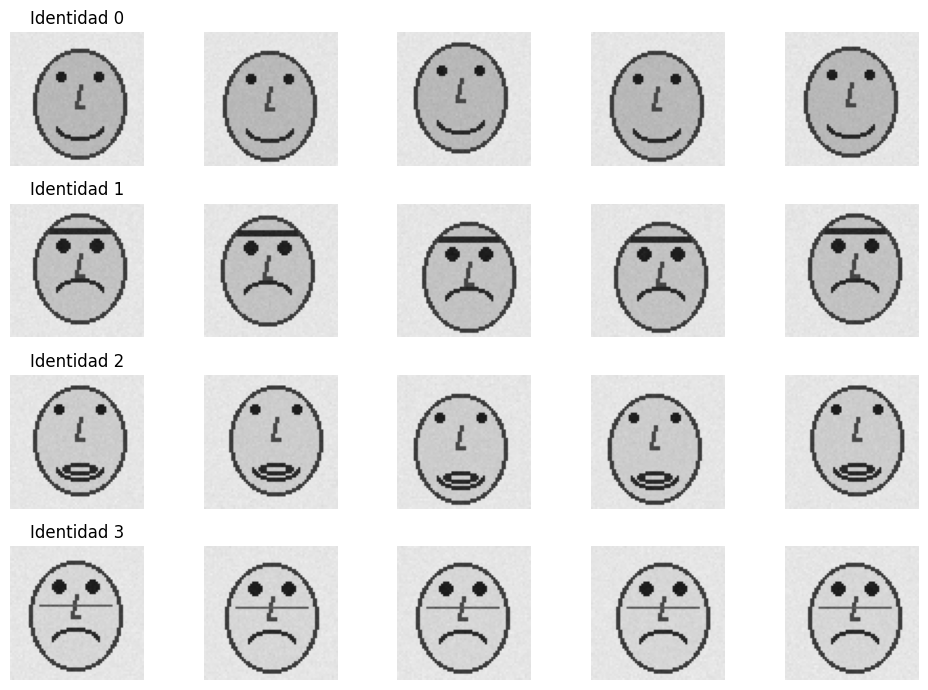

In [ ]:
# Creo una figura con cuatro filas y cinco columnas.
# Cada fila representa una identidad y cada columna una imagen.
fig, axes = plt.subplots(N_ID, 5, figsize=(10, 7))

# Recorro las cuatro identidades.
for i in range(N_ID):

    # Obtengo los índices de las imágenes pertenecientes
    # a la identidad actual y selecciono las primeras cinco.
    idx = np.where(labels == i)[0][:5]

    # Recorro las cinco imágenes seleccionadas.
    for j, k in enumerate(idx):

        # Muestro la imagen correspondiente en escala de grises.
        axes[i, j].imshow(
            images[k],
            cmap='gray',
            vmin=0,
            vmax=255
        )

        # Oculto los ejes para mejorar la presentación visual.
        axes[i, j].axis('off')

        # Coloco el nombre de la identidad en la primera imagen
        # de cada fila.
        if j == 0:
            axes[i, j].set_title(f'Identidad {i}')

# Ajusto automáticamente los espacios entre las imágenes.
plt.tight_layout()

# Presento la figura en pantalla.
plt.show()

In [ ]:
# Convierto el arreglo de imágenes NumPy en un tensor de PyTorch.
# Utilizo float32 porque las operaciones de la red neuronal
# requieren valores numéricos de punto flotante.
X = torch.tensor(images, dtype=torch.float32)

# Agrego una dimensión adicional para representar el canal de color.
# Como las imágenes están en escala de grises, tienen un solo canal.
# Posteriormente divido los valores entre 255 para normalizarlos
# al intervalo comprendido entre 0 y 1.
X = X.unsqueeze(1) / 255.0

# Convierto las etiquetas a tensores de tipo long.
# Este tipo de dato se utiliza habitualmente para representar clases.
y = torch.tensor(labels, dtype=torch.long)

# Muestro las dimensiones del tensor de imágenes.
print('X:', X.shape)

# Muestro las dimensiones del tensor de etiquetas.
print('y:', y.shape)

# Verifico el rango de los valores de las imágenes normalizadas.
print('Rango X:', float(X.min()), float(X.max()))

X: torch.Size([48, 1, 64, 64])
y: torch.Size([48])
Rango X: 0.0784313753247261 0.9450980424880981


In [ ]:
# Defino una clase personalizada que hereda de Dataset.
# Esta clase permite organizar los datos para el entrenamiento
# mediante la técnica Triplet Learning.
class TripletFaces(Dataset):

    # Inicializo la clase con las imágenes, sus etiquetas
    # y la cantidad de tripletas que se generarán por época.
    def __init__(self, X, y, triplets_per_epoch=400):

        # Almaceno los tensores de imágenes.
        self.X = X

        # Almaceno las etiquetas de las identidades.
        self.y = y

        # Establezco la cantidad de tripletas disponibles por época.
        self.n = triplets_per_epoch

        # Agrupo los índices de las imágenes según su identidad.
        # torch.unique obtiene las clases existentes.
        # torch.where encuentra los índices que pertenecen a cada clase.
        # tolist convierte los índices en listas de Python.
        self.by_class = {
            int(c): torch.where(y == c)[0].tolist()
            for c in torch.unique(y)
        }

        # Obtengo la lista de identidades disponibles.
        self.classes = list(self.by_class)

    # Defino la longitud del conjunto de datos.
    # En este caso corresponde a la cantidad de tripletas por época.
    def __len__(self):
        return self.n

    # Defino cómo se obtiene una tripleta individual.
    def __getitem__(self, idx):

        # Selecciono aleatoriamente una identidad para el Anchor.
        a_class = random.choice(self.classes)

        # Construyo una lista con las identidades diferentes
        # a la seleccionada para el Anchor.
        other_classes = [
            c for c in self.classes
            if c != a_class
        ]

        # Selecciono aleatoriamente una identidad diferente
        # para generar el ejemplo Negative.
        n_class = random.choice(other_classes)

        # Selecciono dos imágenes diferentes de la misma identidad:
        # una será el Anchor y la otra será el Positive.
        a_idx, p_idx = random.sample(
            self.by_class[a_class], 2
        )

        # Selecciono una imagen perteneciente a otra identidad.
        n_idx = random.choice(
            self.by_class[n_class]
        )

        # Retorno las tres imágenes y sus respectivas identidades.
        return (
            self.X[a_idx],
            self.X[p_idx],
            self.X[n_idx],
            a_class,
            n_class
        )

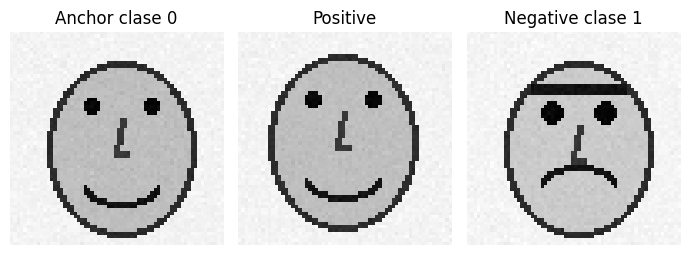

In [ ]:
# Creo el conjunto de datos TripletFaces.
# Establezco 400 tripletas disponibles por época de entrenamiento.
trip = TripletFaces(X, y, triplets_per_epoch=400)

# Obtengo la primera tripleta del conjunto de datos.
# a representa Anchor, p representa Positive y n representa Negative.
# ca y cn almacenan las identidades correspondientes.
a, p, n, ca, cn = trip[0]

# Creo una figura con tres espacios de visualización.
fig, ax = plt.subplots(1, 3, figsize=(7, 2.5))

# Recorro las tres imágenes junto con sus títulos y ejes.
for tensor_img, title, axis in [
    (a, f'Anchor clase {ca}', ax[0]),
    (p, 'Positive', ax[1]),
    (n, f'Negative clase {cn}', ax[2])
]:

    # Elimino las dimensiones adicionales del tensor
    # para poder mostrar correctamente la imagen.
    axis.imshow(tensor_img.squeeze(), cmap='gray')

    # Asigno el título correspondiente a cada imagen.
    axis.set_title(title)

    # Oculto los ejes de coordenadas.
    axis.axis('off')

# Ajusto la distribución de las imágenes.
plt.tight_layout()

# Muestro la figura.
plt.show()


In [ ]:
# Defino la arquitectura Encoder heredando de nn.Module.
# Esta clase representa la red neuronal encargada de extraer
# características y generar embeddings de los rostros.
class Encoder(nn.Module):

    # Inicializo la arquitectura.
    # emb_dim determina la cantidad de valores de cada embedding.
    def __init__(self, emb_dim=64):

        # Inicializo correctamente la clase padre de PyTorch.
        super().__init__()

        # Defino las capas encargadas de extraer características.
        self.features = nn.Sequential(

            # Primera capa convolucional.
            # Recibe 1 canal de entrada y genera 8 mapas de características.
            # Utiliza filtros de 3x3 y padding=1 para conservar
            # las dimensiones espaciales.
            nn.Conv2d(1, 8, 3, padding=1),

            # Aplico la función de activación ReLU.
            nn.ReLU(),

            # Reduzco las dimensiones espaciales a la mitad.
            nn.MaxPool2d(2),

            # Segunda capa convolucional.
            # Recibe 8 mapas y genera 16 mapas de características.
            nn.Conv2d(8, 16, 3, padding=1),

            # Aplico nuevamente la función ReLU.
            nn.ReLU(),

            # Reduzco nuevamente las dimensiones espaciales.
            nn.MaxPool2d(2),

            # Tercera capa convolucional.
            # Recibe 16 mapas y genera 32 mapas de características.
            nn.Conv2d(16, 32, 3, padding=1),

            # Aplico la función de activación ReLU.
            nn.ReLU(),

            # Ajusto la salida a mapas de características de 4x4.
            # Esto permite obtener una dimensión espacial fija.
            nn.AdaptiveAvgPool2d((4, 4))
        )

        # Defino una capa completamente conectada.
        # Recibe 32 mapas de 4x4 = 512 características
        # y genera un embedding de 64 dimensiones.
        self.fc = nn.Linear(32 * 4 * 4, emb_dim)

    # Defino el proceso de propagación hacia adelante.
    # Aquí se establece cómo fluye la información por la red.
    def forward(self, x):

        # Extraigo las características mediante las capas convolucionales.
        z = self.features(x)

        # Aplano las dimensiones espaciales y los canales.
        # Se conserva la dimensión correspondiente al lote de imágenes.
        z = z.flatten(1)

        # Transformo las características en un embedding de 64 dimensiones.
        z = self.fc(z)

        # Normalizo cada embedding utilizando la norma L2.
        # Esto permite que los vectores tengan longitud unitaria.
        z = F.normalize(z, p=2, dim=1)

        # Retorno la representación numérica del rostro.
        return z

In [ ]:
# Creo una instancia de la red neuronal Encoder.
# Establezco que cada rostro se represente mediante 64 valores.
# También traslado el modelo al dispositivo seleccionado.
model = Encoder(emb_dim=64).to(DEVICE)

# Muestro la estructura de la red neuronal.
print(model)

# Desactivo el cálculo de gradientes porque en esta prueba
# únicamente necesito verificar la salida del modelo.
with torch.no_grad():

    # Selecciono las dos primeras imágenes del conjunto de datos,
    # las traslado al dispositivo y las paso por la red neuronal.
    example_embedding = model(
        X[:2].to(DEVICE)
    )

# Muestro las dimensiones de los embeddings generados.
print(
    'Embedding de ejemplo:',
    example_embedding.shape
)


Encoder(
  (features): Sequential(
    (0): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (fc): Linear(in_features=512, out_features=64, bias=True)
)
Embedding de ejemplo: torch.Size([2, 64])


In [ ]:
# Creo un DataLoader para suministrar las tripletas al modelo.
loader = DataLoader(

    # Conjunto de datos que contiene las tripletas.
    trip,

    # Cantidad de tripletas procesadas en cada lote.
    batch_size=32,

    # Mezclo aleatoriamente las muestras durante el entrenamiento.
    shuffle=True
)

# Defino la función de pérdida Triplet Margin Loss.
criterion = nn.TripletMarginLoss(

    # Margen mínimo que debe existir entre las distancias
    # del Anchor-Positive y Anchor-Negative.
    margin=0.8,

    # Utilizo la distancia euclidiana, correspondiente a p=2.
    p=2
)

# Defino el optimizador Adam.
optimizer = torch.optim.Adam(

    # Parámetros de la red neuronal que serán actualizados.
    model.parameters(),

    # Tasa de aprendizaje utilizada para actualizar los pesos.
    lr=1e-3
)

In [ ]:
# Creo una lista para almacenar la pérdida promedio de cada época.
losses = []

# Inicio el entrenamiento durante 18 épocas.
for epoch in range(18):

    # Coloco el modelo en modo entrenamiento.
    # Esto permite activar los comportamientos específicos
    # de entrenamiento de las capas que los utilizan.
    model.train()

    # Inicializo el acumulador de pérdidas.
    total = 0

    # Inicializo el contador de muestras procesadas.
    count = 0

    # Recorro los lotes de tripletas suministrados por el DataLoader.
    for a, p, n, _, _ in loader:

        # Traslado las imágenes Anchor al dispositivo seleccionado.
        a = a.to(DEVICE)

        # Traslado las imágenes Positive al dispositivo seleccionado.
        p = p.to(DEVICE)

        # Traslado las imágenes Negative al dispositivo seleccionado.
        n = n.to(DEVICE)

        # Paso las imágenes Anchor por la red neuronal.
        # Obtengo su representación numérica.
        za = model(a)

        # Paso las imágenes Positive por la red neuronal.
        zp = model(p)

        # Paso las imágenes Negative por la red neuronal.
        zn = model(n)

        # Calculo la función de pérdida utilizando los tres embeddings.
        loss = criterion(za, zp, zn)

        # Limpio los gradientes acumulados de la iteración anterior.
        optimizer.zero_grad()

        # Realizo la retropropagación para calcular los gradientes.
        loss.backward()

        # Actualizo los parámetros de la red neuronal mediante Adam.
        optimizer.step()

        # Acumulo la pérdida multiplicada por la cantidad de imágenes
        # del lote para calcular posteriormente el promedio.
        total += loss.item() * a.size(0)

        # Actualizo el contador de muestras procesadas.
        count += a.size(0)

    # Calculo la pérdida promedio de la época.
    mean_loss = total / count

    # Almaceno la pérdida promedio en la lista.
    losses.append(mean_loss)

    # Muestro los resultados de determinadas épocas.
    if epoch in [0, 1, 2, 5, 10, 17]:

        # Presento el número de época y el valor de la pérdida.
        print(
            f'Época {epoch+1:02d} | '
            f'loss={mean_loss:.4f}'
        )

Época 01 | loss=0.4246
Época 02 | loss=0.0638
Época 03 | loss=0.0035
Época 06 | loss=0.0002
Época 11 | loss=0.0000
Época 18 | loss=0.0007


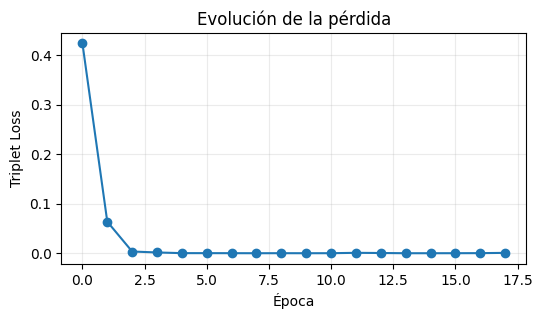

In [ ]:
# Creo una figura para representar gráficamente los resultados.
plt.figure(figsize=(6, 3))

# Grafico los valores de pérdida almacenados durante el entrenamiento.
# marker='o' agrega un marcador circular en cada época.
plt.plot(losses, marker='o')

# Asigno el nombre al eje horizontal.
plt.xlabel('Época')

# Asigno el nombre al eje vertical.
plt.ylabel('Triplet Loss')

# Establezco el título de la gráfica.
plt.title('Evolución de la pérdida')

# Agrego una cuadrícula con transparencia del 25 %.
plt.grid(alpha=.25)

# Muestro la gráfica.
plt.show()

In [ ]:
# Coloco el modelo en modo evaluación.
model.eval()

# Desactivo el cálculo de gradientes porque no voy a entrenar.
with torch.no_grad():

    # Paso todas las imágenes por la red neuronal.
    # Posteriormente traslado los resultados a la CPU.
    Z = model(
        X.to(DEVICE)
    ).cpu()

# Muestro las dimensiones de la matriz de embeddings.
print('Forma de Z:', Z.shape)

# Repito la configuración del modo evaluación.
model.eval()

# Desactivo nuevamente el cálculo de gradientes.
with torch.no_grad():

    # Vuelvo a generar los embeddings de todas las imágenes.
    Z = model(
        X.to(DEVICE)
    ).cpu()

# Muestro las dimensiones obtenidas.
print('Forma de Z:', Z.shape)

Forma de Z: torch.Size([48, 64])
Forma de Z: torch.Size([48, 64])


Distancia positiva media: 0.1473
Distancia negativa media: 1.5805


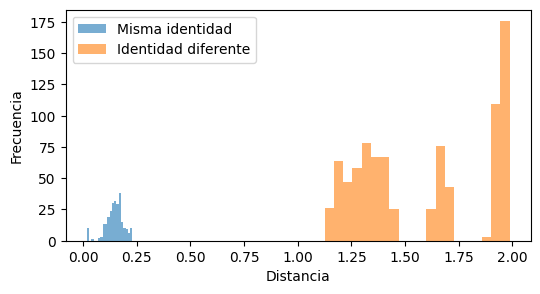

In [ ]:
# Creo una lista para almacenar las distancias
# entre imágenes de la misma identidad.
pos = []

# Creo una lista para almacenar las distancias
# entre imágenes de identidades diferentes.
neg = []

# Recorro todas las imágenes del conjunto de datos.
for i in range(len(X)):

    # Comparo cada imagen con las imágenes que aparecen
    # después de ella para evitar comparaciones duplicadas.
    for j in range(i + 1, len(X)):

        # Calculo la distancia euclidiana entre dos embeddings.
        # torch.dist utiliza la norma L2 por defecto.
        # item() convierte el resultado en un valor numérico de Python.
        distance = torch.dist(
            Z[i], Z[j]
        ).item()

        # Verifico si las dos imágenes pertenecen a la misma identidad.
        if labels[i] == labels[j]:

            # Si pertenecen a la misma identidad,
            # almaceno la distancia en la lista positiva.
            pos.append(distance)

        else:

            # Si pertenecen a identidades diferentes,
            # almaceno la distancia en la lista negativa.
            neg.append(distance)

# Calculo y muestro la distancia promedio entre imágenes
# pertenecientes a la misma identidad.
print(
    'Distancia positiva media:',
    round(float(np.mean(pos)), 4)
)

# Calculo y muestro la distancia promedio entre imágenes
# pertenecientes a identidades diferentes.
print(
    'Distancia negativa media:',
    round(float(np.mean(neg)), 4)
)

# Creo una figura para comparar las distribuciones de distancias.
plt.figure(figsize=(6, 3))

# Represento la distribución de las distancias positivas.
plt.hist(
    pos, bins=20, alpha=.6,
    label='Misma identidad'
)

# Represento la distribución de las distancias negativas.
plt.hist(
    neg, bins=20, alpha=.6,
    label='Identidad diferente'
)

# Agrego la leyenda para identificar ambas distribuciones.
plt.legend()

# Asigno el nombre al eje horizontal.
plt.xlabel('Distancia')

# Asigno el nombre al eje vertical.
plt.ylabel('Frecuencia')

# Muestro el histograma.
plt.show()

In [ ]:
# Creo un diccionario con una imagen de referencia por identidad.
refs = {
    c: np.where(labels == c)[0][0]
    for c in range(N_ID)
}

# Creo una lista con los índices de las imágenes que serán consultas.
# Excluyo las imágenes que ya fueron seleccionadas como referencias.
queries = [
    i for i in range(len(X))
    if i not in refs.values()
]

# Inicializo el contador de predicciones correctas.
correct = 0

# Recorro todas las imágenes de consulta.
for i in queries:

    # Calculo la distancia entre el embedding de la consulta
    # y el embedding de cada imagen de referencia.
    dists = {
        c: torch.dist(
            Z[i], Z[idx]
        ).item()
        for c, idx in refs.items()
    }

    # Selecciono la identidad que presenta la menor distancia.
    # min() devuelve la clave cuyo valor es más pequeño.
    pred = min(dists, key=dists.get)

    # Comparo la predicción con la identidad verdadera.
    # Si coinciden, incremento el contador de aciertos.
    correct += int(pred == labels[i])

# Calculo la exactitud dividiendo los aciertos
# entre el total de imágenes utilizadas como consulta.
acc_one = correct / len(queries)

# Muestro la exactitud obtenida y la cantidad de aciertos.
print(
    'Accuracy One-shot:',
    round(acc_one, 4),
    f'({correct}/{len(queries)})'
)

Accuracy One-shot: 1.0 (44/44)


In [ ]:
# Creo un diccionario con los índices de las tres primeras imágenes
# correspondientes a cada identidad.
ref_ids = {
    c: np.where(labels == c)[0][:3]
    for c in range(N_ID)
}

# Creo un diccionario vacío para almacenar los prototipos.
prototypes = {}

# Recorro las identidades y sus respectivas imágenes de referencia.
for c, idx in ref_ids.items():

    # Calculo el promedio de los embeddings de las tres imágenes.
    # dim=0 indica que el promedio se calcula entre las imágenes.
    # keepdim=True conserva la dimensión del resultado.
    proto = Z[idx].mean(
        0, keepdim=True
    )

    # Normalizo el prototipo utilizando la norma L2.
    proto = F.normalize(
        proto, p=2, dim=1
    )

    # Almaceno el prototipo correspondiente a la identidad.
    # squeeze(0) elimina la primera dimensión de tamaño uno.
    prototypes[c] = proto.squeeze(0)

# Creo la lista de imágenes de consulta.
# Excluyo todas las imágenes utilizadas como referencia.
query_ids = [
    i for i in range(len(X))
    if all(
        i not in ids
        for ids in ref_ids.values()
    )
]

# Inicializo el contador de predicciones correctas.
correct = 0

# Recorro todas las imágenes de consulta.
for i in query_ids:

    # Calculo la distancia entre el embedding de la consulta
    # y cada uno de los prototipos de las identidades.
    dists = {
        c: torch.dist(
            Z[i], proto
        ).item()
        for c, proto in prototypes.items()
    }

    # Selecciono la identidad cuyo prototipo presenta
    # la menor distancia respecto a la imagen consultada.
    pred = min(dists, key=dists.get)

    # Comparo la identidad predicha con la identidad verdadera.
    correct += int(pred == labels[i])

# Calculo la exactitud del reconocimiento Few-shot.
acc_few = correct / len(query_ids)

# Muestro la exactitud obtenida y el número de aciertos.
print(
    'Accuracy Few-shot:',
    round(acc_few, 4),
    f'({correct}/{len(query_ids)})'
)

# Comparo los resultados obtenidos mediante One-shot y Few-shot.
print(
    'Comparación -> One-shot:',
    round(acc_one, 4),
    '| Few-shot:',
    round(acc_few, 4)
)

Accuracy Few-shot: 1.0 (36/36)
Comparación -> One-shot: 1.0 | Few-shot: 1.0


In [ ]:
# Calculo un umbral utilizando el promedio de las distancias positivas
# y el promedio de las distancias negativas.
threshold = (
    float(np.mean(pos)) +
    float(np.mean(neg))
) / 2

# Muestro el valor del umbral calculado.
print(
    'Umbral pedagógico:',
    round(threshold, 4)
)

# Defino una función para verificar si dos imágenes
# pertenecen a la misma identidad.
def verify(i, j):

    # Calculo la distancia euclidiana entre los embeddings.
    distance = torch.dist(
        Z[i], Z[j]
    ).item()

    # Si la distancia es inferior al umbral,
    # clasifico las imágenes como pertenecientes a la misma identidad.
    same_identity = distance < threshold

    # Retorno la distancia y el resultado de la verificación.
    return distance, same_identity

# Selecciono las dos primeras imágenes de la identidad 0.
same = np.where(labels == 0)[0][:2]

# Selecciono una imagen de la identidad 0
# y otra imagen perteneciente a la identidad 1.
diff = (
    np.where(labels == 0)[0][0],
    np.where(labels == 1)[0][0]
)

# Evalúo un par de imágenes de la misma identidad
# y otro par de identidades diferentes.
for pair in [tuple(same), diff]:

    # Ejecuto la función de verificación.
    distance, ok = verify(*pair)

    # Convierto el resultado booleano en un texto descriptivo.
    result = 'MISMA' if ok else 'DIFERENTE'

    # Muestro los índices, la distancia y la clasificación.
    print(
        pair,
        'dist=', round(distance, 4),
        '=>', result
    )

Umbral pedagógico: 0.8639
(np.int64(0), np.int64(1)) dist= 0.1415 => MISMA
(np.int64(0), np.int64(12)) dist= 1.6406 => DIFERENTE


In [ ]:
# Importo Path para facilitar la manipulación de rutas y directorios.
from pathlib import Path

# Defino una función para cargar fotografías autorizadas.
# root representa la carpeta principal donde se almacenan las fotografías.
# size establece las dimensiones a las que se ajustarán las imágenes.
def load_authorized_faces(
    root='/content/rostros',
    size=(64, 64)
):

    # Convierto la ruta recibida en un objeto Path.
    root = Path(root)

    # Creo una lista para almacenar las imágenes procesadas.
    imgs = []

    # Creo una lista para almacenar las etiquetas de las personas.
    labs = []

    # Creo una lista para almacenar los nombres de las personas.
    names = []

    # Verifico si existe el directorio principal.
    if not root.exists():

        # Informo que la carpeta todavía no está disponible.
        print('Aún no existe', root)

        # Retorno valores nulos porque no hay datos para cargar.
        return None, None, None

    # Identifico las carpetas correspondientes a cada persona.
    # sorted permite mantener un orden alfabético.
    persons = sorted([
        p for p in root.iterdir()
        if p.is_dir()
    ])

    # Recorro las carpetas y asigno una etiqueta numérica a cada persona.
    for label, person in enumerate(persons):

        # Almaceno el nombre de la persona.
        names.append(person.name)

        # Recorro los archivos de la carpeta correspondiente.
        for fp in sorted(person.glob('*')):

            # Verifico que el archivo tenga una extensión de imagen válida.
            if fp.suffix.lower() not in {
                '.jpg', '.jpeg', '.png', '.webp'
            }:
                continue

            # Abro la imagen.
            img = Image.open(fp)

            # Convierto la imagen a escala de grises.
            # Posteriormente ajusto sus dimensiones al tamaño establecido.
            img = img.convert('L').resize(size)

            # Convierto la imagen en un arreglo NumPy de tipo uint8.
            imgs.append(
                np.array(img, dtype=np.uint8)
            )

            # Almaceno la etiqueta correspondiente a la persona.
            labs.append(label)

    # Verifico si se encontraron imágenes.
    if not imgs:

        # Informo que no se encontraron fotografías.
        print('No se encontraron imágenes.')

        # Retorno valores nulos para los datos y las etiquetas.
        # Mantengo los nombres de las personas encontrados.
        return None, None, names

    # Agrupo las imágenes y las convierto en un tensor de PyTorch.
    # Utilizo float32, agrego la dimensión del canal y normalizo
    # los valores de los píxeles entre 0 y 1.
    Xr = torch.tensor(
        np.stack(imgs),
        dtype=torch.float32
    ).unsqueeze(1) / 255.0

    # Convierto las etiquetas en un tensor de tipo long.
    yr = torch.tensor(
        labs,
        dtype=torch.long
    )

    # Muestro los nombres de las personas encontradas.
    print('Personas:', names)

    # Muestro las dimensiones de las imágenes y las etiquetas.
    print('Xr:', Xr.shape, 'yr:', yr.shape)

    # Retorno los tensores de imágenes, etiquetas y nombres.
    return Xr, yr, names

In [ ]:
# Estructura sugerida:
# /content/rostros/
#   persona_01/
#       foto1.jpg
#       foto2.jpg
#       foto3.jpg
#   persona_02/
#       foto1.jpg
#       foto2.jpg
#       foto3.jpg

Xr, yr, names = load_authorized_faces(
    '/content/rostros'
)


Aún no existe \content\rostros


In [ ]:
# Verifico si la variable model existe en el entorno actual.
print('Modelo disponible:', 'model' in globals())

# Verifico si la variable DEVICE existe en el entorno actual.
print('DEVICE disponible:', 'DEVICE' in globals())

# Compruebo si alguna de las dos variables no está definida.
if 'model' not in globals() or 'DEVICE' not in globals():

    # Informo que primero se debe ejecutar el entrenamiento principal.
    print('Debes ejecutar primero la práctica principal de Redes Neuronales V.')

else:

    # Confirmo que el entorno está preparado para continuar.
    print('Podemos continuar con fotografías reales.')

Modelo disponible: True
DEVICE disponible: True
Podemos continuar con fotografías reales.


In [ ]:
# Importo os para gestionar directorios y rutas.
import os

# Importo shutil para copiar y eliminar directorios.
import shutil

# Importo Path para facilitar la manipulación de rutas.
from pathlib import Path

# Importo NumPy para trabajar con arreglos numéricos.
import numpy as np

# Importo Matplotlib para visualizar las fotografías.
import matplotlib.pyplot as plt

# Importo Image e ImageOps para abrir y procesar imágenes.
from PIL import Image, ImageOps

# Importo PyTorch para trabajar con tensores.
import torch

# Importo las funciones de PyTorch relacionadas con redes neuronales.
import torch.nn.functional as F

# Importo files para permitir la carga de archivos desde Google Colab.
from google.colab import files

# Confirmo que las bibliotecas se importaron correctamente.
print('Librerías cargadas correctamente')

Librerías cargadas correctamente


In [ ]:
# Defino la ruta principal donde se almacenarán las fotografías.
ruta_base = '/content/rostros'

# Verifico si el directorio principal ya existe.
if os.path.exists(ruta_base):

    # Elimino el directorio existente y todo su contenido.
    shutil.rmtree(ruta_base)

# Creo la carpeta correspondiente a la Persona 1.
# exist_ok=True evita generar un error si ya existe.
os.makedirs('/content/rostros/persona_01', exist_ok=True)

# Creo la carpeta correspondiente a la Persona 2.
os.makedirs('/content/rostros/persona_02', exist_ok=True)

# Informo las carpetas que fueron preparadas.
print('Carpetas preparadas:')
print('/content/rostros/persona_01')
print('/content/rostros/persona_02')

Carpetas preparadas:
/content/rostros/persona_01
/content/rostros/persona_02


In [ ]:
# Solicito seleccionar exactamente tres fotografías de la Persona 1.
print('Seleccione EXACTAMENTE 3 fotografías de PERSONA 1')

# Abro el selector de archivos de Google Colab.
fotos_persona1 = files.upload()

# Verifico si la cantidad de archivos cargados es igual a tres.
if len(fotos_persona1) != 3:

    # Muestro una advertencia si la cantidad de fotografías es diferente.
    print('ADVERTENCIA: se esperaban 3 archivos y se cargaron', len(fotos_persona1))

# Recorro los archivos seleccionados.
for nombre, contenido in fotos_persona1.items():

    # Construyo la ruta donde se almacenará cada fotografía.
    ruta = '/content/rostros/persona_01/' + nombre

    # Abro el archivo en modo escritura binaria.
    with open(ruta, 'wb') as archivo:

        # Escribo el contenido de la fotografía en el archivo.
        archivo.write(contenido)

# Muestro la cantidad de fotografías guardadas.
print('Fotos de Persona 1 guardadas:', len(fotos_persona1))

Seleccione EXACTAMENTE 3 fotografías de PERSONA 1


NameError: name 'files' is not defined

In [ ]:
# Solicito seleccionar exactamente tres fotografías de la Persona 2.
print('Seleccione EXACTAMENTE 3 fotografías de PERSONA 2')

# Abro el selector de archivos de Google Colab.
fotos_persona2 = files.upload()

# Compruebo si se seleccionaron tres archivos.
if len(fotos_persona2) != 3:

    # Muestro una advertencia si la cantidad no coincide.
    print('ADVERTENCIA: se esperaban 3 archivos y se cargaron', len(fotos_persona2))

# Recorro los archivos seleccionados.
for nombre, contenido in fotos_persona2.items():

    # Construyo la ruta de almacenamiento de cada fotografía.
    ruta = '/content/rostros/persona_02/' + nombre

    # Abro el archivo en modo escritura binaria.
    with open(ruta, 'wb') as archivo:

        # Guardo el contenido de la fotografía.
        archivo.write(contenido)

# Muestro la cantidad de fotografías almacenadas.
print('Fotos de Persona 2 guardadas:', len(fotos_persona2))

Seleccione EXACTAMENTE 3 fotografías de PERSONA 2


NameError: name 'files' is not defined

In [ ]:
# Inicializo un contador para registrar la cantidad de archivos.
total = 0

# Recorro el directorio principal y todas sus subcarpetas.
for carpeta, subcarpetas, archivos in os.walk('/content/rostros'):

    # Muestro el nombre del directorio que estoy recorriendo.
    print('Carpeta:', carpeta)

    # Recorro los archivos encontrados dentro del directorio.
    for archivo in archivos:

        # Muestro el nombre de cada archivo.
        print('   ', archivo)

        # Incremento el contador de archivos.
        total += 1

# Muestro la cantidad total de archivos encontrados.
print('Total de archivos encontrados:', total)

Carpeta: /content/rostros
Carpeta: /content/rostros/persona_01
    WhatsApp Image 2026-10-29 at 10.26.34 PM.jpeg
    WhatsApp Image 2026-10-29 at 10.29.06 PM.jpeg
    WhatsApp Image 2026-10-29 at 10.26.52 PM.jpeg
Carpeta: /content/rostros/persona_02
    WhatsApp Image 2026-10-29 at 10.24.43 PM.jpeg
    WhatsApp Image 2026-10-29 at 10.24.02 PM.jpeg
    WhatsApp Image 2026-10-29 at 10.22.06 PM.jpeg
Total de archivos encontrados: 6


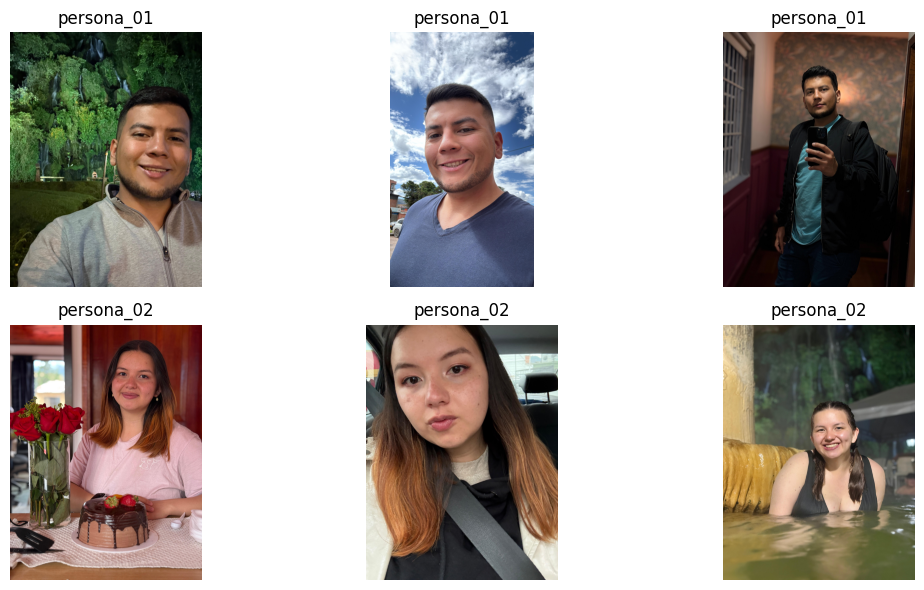

In [ ]:
# Defino las rutas de las carpetas que contienen las fotografías.
carpetas = [
    '/content/rostros/persona_01',
    '/content/rostros/persona_02'
]

# Creo una figura para visualizar las seis fotografías.
plt.figure(figsize=(12, 6))

# Inicializo la posición de la primera imagen.
posicion = 1

# Recorro las carpetas de las dos personas.
for carpeta in carpetas:

    # Obtengo el nombre de la persona a partir de la ruta.
    persona = os.path.basename(carpeta)

    # Recorro los archivos ordenados alfabéticamente.
    for archivo in sorted(os.listdir(carpeta)):

        # Construyo la ruta completa de la fotografía.
        ruta = os.path.join(carpeta, archivo)

        # Abro la fotografía y la convierto al formato RGB
        # para visualizarla correctamente.
        imagen = Image.open(ruta).convert('RGB')

        # Ubico la imagen dentro de una cuadrícula de dos filas
        # y tres columnas.
        plt.subplot(2, 3, posicion)

        # Muestro la fotografía.
        plt.imshow(imagen)

        # Coloco el nombre de la persona como título.
        plt.title(persona)

        # Oculto los ejes de coordenadas.
        plt.axis('off')

        # Avanzo a la siguiente posición de la cuadrícula.
        posicion += 1

# Ajusto los espacios entre las imágenes.
plt.tight_layout()

# Presento las fotografías.
plt.show()

In [ ]:
# Defino una función para cargar fotografías desde un directorio.
# carpeta establece la ubicación de las fotografías.
# tamano define las dimensiones finales de cada imagen.
def cargar_rostros(carpeta='/content/rostros', tamano=(64, 64)):

    # Convierto la ruta en un objeto Path.
    carpeta = Path(carpeta)

    # Creo una lista para almacenar las imágenes procesadas.
    imagenes = []

    # Creo una lista para almacenar las etiquetas.
    etiquetas = []

    # Creo una lista para almacenar los nombres de las personas.
    nombres_personas = []

    # Identifico las carpetas de las personas y las ordeno.
    personas = sorted([p for p in carpeta.iterdir() if p.is_dir()])

    # Recorro cada carpeta y asigno una etiqueta numérica.
    for etiqueta, persona in enumerate(personas):

        # Almaceno el nombre de la persona.
        nombres_personas.append(persona.name)

        # Informo qué persona estoy procesando.
        print('Leyendo:', persona.name)

        # Recorro los archivos de la carpeta actual.
        for archivo in sorted(persona.glob('*')):

            # Verifico que el archivo tenga una extensión de imagen válida.
            if archivo.suffix.lower() not in {'.jpg', '.jpeg', '.png', '.webp'}:
                continue

            # Abro la imagen y la convierto a escala de grises.
            imagen = Image.open(archivo).convert('L')

            # Ajusto la imagen al tamaño establecido.
            # ImageOps.fit permite ajustar el tamaño conservando
            # la relación de aspecto mediante recorte cuando es necesario.
            imagen = ImageOps.fit(imagen, tamano)

            # Convierto la imagen en un arreglo NumPy de tipo uint8.
            imagen = np.array(imagen, dtype=np.uint8)

            # Agrego la imagen procesada a la lista.
            imagenes.append(imagen)

            # Agrego la etiqueta correspondiente a la persona.
            etiquetas.append(etiqueta)

    # Agrupo las imágenes y las convierto en un tensor float32.
    Xr = torch.tensor(np.stack(imagenes), dtype=torch.float32)

    # Agrego la dimensión del canal y normalizo los píxeles entre 0 y 1.
    Xr = Xr.unsqueeze(1) / 255.0

    # Convierto las etiquetas en un tensor de tipo long.
    yr = torch.tensor(etiquetas, dtype=torch.long)

    # Retorno las imágenes, las etiquetas y los nombres de las personas.
    return Xr, yr, nombres_personas

In [ ]:
# Cargo las fotografías reales, sus etiquetas y los nombres
# de las personas almacenadas en el directorio.
Xr, yr, nombres = cargar_rostros('/content/rostros')

# Muestro las personas identificadas en las carpetas.
print('Personas encontradas:', nombres)

# Muestro las dimensiones del tensor de fotografías.
print('Forma de las imágenes:', Xr.shape)

# Muestro las etiquetas asignadas a cada fotografía.
print('Etiquetas:', yr)

Leyendo: persona_01
Leyendo: persona_02
Personas encontradas: ['persona_01', 'persona_02']
Forma de las imágenes: torch.Size([6, 1, 64, 64])
Etiquetas: tensor([0, 0, 0, 1, 1, 1])


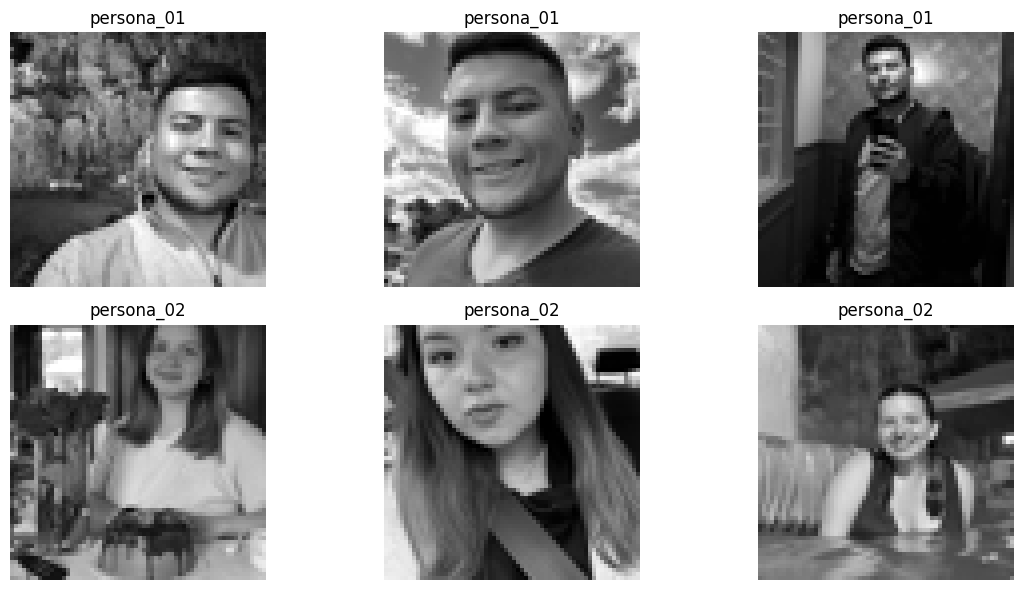

In [ ]:
# Creo una figura para mostrar las fotografías procesadas.
plt.figure(figsize=(12, 6))

# Recorro todas las imágenes almacenadas en Xr.
for i in range(len(Xr)):

    # Ubico cada fotografía dentro de una cuadrícula de dos filas
    # y tres columnas.
    plt.subplot(2, 3, i + 1)

    # Elimino las dimensiones adicionales del tensor
    # y muestro la imagen en escala de grises.
    plt.imshow(Xr[i].squeeze(), cmap='gray')

    # Obtengo el nombre de la persona utilizando su etiqueta.
    plt.title(nombres[yr[i].item()])

    # Oculto los ejes de coordenadas.
    plt.axis('off')

# Ajusto los espacios de visualización.
plt.tight_layout()

# Muestro las fotografías procesadas.
plt.show()

In [ ]:
# Selecciono la primera fotografía de la Persona 1 como Anchor.
anchor = Xr[0]       # Persona 1

# Selecciono la segunda fotografía de la Persona 1 como Positive.
positive = Xr[1]     # Persona 1

# Selecciono la primera fotografía de la Persona 2 como Negative.
negative = Xr[3]     # Persona 2

# Muestro las dimensiones del tensor Anchor.
print('Anchor:', anchor.shape)

# Muestro las dimensiones del tensor Positive.
print('Positive:', positive.shape)

# Muestro las dimensiones del tensor Negative.
print('Negative:', negative.shape)

Anchor: torch.Size([1, 64, 64])
Positive: torch.Size([1, 64, 64])
Negative: torch.Size([1, 64, 64])


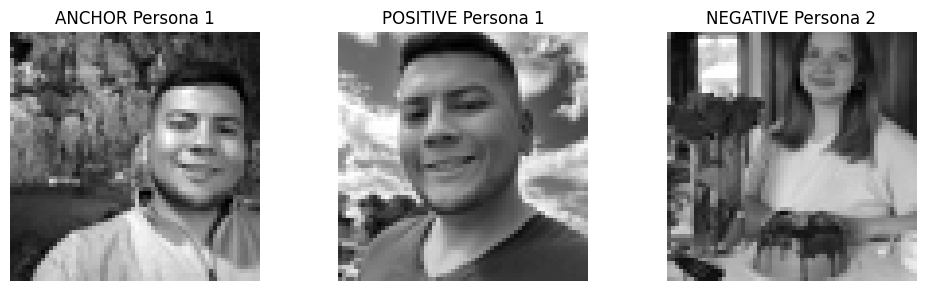

In [ ]:
# Creo una figura para mostrar las tres fotografías.
plt.figure(figsize=(10, 3))

# Ubico la fotografía Anchor en la primera posición.
plt.subplot(1, 3, 1)

# Muestro la imagen Anchor en escala de grises.
plt.imshow(anchor.squeeze(), cmap='gray')

# Identifico la imagen como Anchor de la Persona 1.
plt.title('ANCHOR Persona 1')

# Oculto los ejes.
plt.axis('off')

# Ubico la fotografía Positive en la segunda posición.
plt.subplot(1, 3, 2)

# Muestro la imagen Positive.
plt.imshow(positive.squeeze(), cmap='gray')

# Identifico la imagen como Positive de la Persona 1.
plt.title('POSITIVE Persona 1')

# Oculto los ejes.
plt.axis('off')

# Ubico la fotografía Negative en la tercera posición.
plt.subplot(1, 3, 3)

# Muestro la imagen Negative.
plt.imshow(negative.squeeze(), cmap='gray')

# Identifico la imagen como Negative de la Persona 2.
plt.title('NEGATIVE Persona 2')

# Oculto los ejes.
plt.axis('off')

# Ajusto los espacios entre las imágenes.
plt.tight_layout()

# Presento las fotografías.
plt.show()

In [ ]:
# Coloco el modelo en modo evaluación.
model.eval()

# Desactivo el cálculo de gradientes porque solamente
# voy a realizar inferencia y no entrenamiento.
with torch.no_grad():

    # Agrego una dimensión de lote al tensor Anchor
    # y lo traslado al dispositivo de procesamiento.
    anchor_batch = anchor.unsqueeze(0).to(DEVICE)

    # Agrego una dimensión de lote al tensor Positive
    # y lo traslado al dispositivo de procesamiento.
    positive_batch = positive.unsqueeze(0).to(DEVICE)

    # Agrego una dimensión de lote al tensor Negative
    # y lo traslado al dispositivo de procesamiento.
    negative_batch = negative.unsqueeze(0).to(DEVICE)

    # Obtengo el embedding correspondiente al Anchor.
    embedding_anchor = model(anchor_batch)

    # Obtengo el embedding correspondiente al Positive.
    embedding_positive = model(positive_batch)

    # Obtengo el embedding correspondiente al Negative.
    embedding_negative = model(negative_batch)

# Muestro las dimensiones del embedding Anchor.
print('Embedding Anchor:', embedding_anchor.shape)

# Muestro las dimensiones del embedding Positive.
print('Embedding Positive:', embedding_positive.shape)

# Muestro las dimensiones del embedding Negative.
print('Embedding Negative:', embedding_negative.shape)

Embedding Anchor: torch.Size([1, 64])
Embedding Positive: torch.Size([1, 64])
Embedding Negative: torch.Size([1, 64])


In [ ]:
# Muestro un mensaje indicando que presentaré los valores del Anchor.
print('Primeros 10 valores del Anchor:')

# Selecciono y muestro los primeros diez componentes del embedding Anchor.
print(embedding_anchor[0][:10])

# Muestro un mensaje indicando que presentaré los valores del Positive.
print('Primeros 10 valores del Positive:')

# Selecciono y muestro los primeros diez componentes del embedding Positive.
print(embedding_positive[0][:10])

# Muestro un mensaje indicando que presentaré los valores del Negative.
print('Primeros 10 valores del Negative:')

# Selecciono y muestro los primeros diez componentes del embedding Negative.
print(embedding_negative[0][:10])

Primeros 10 valores del Anchor:
tensor([-0.0015,  0.2023, -0.0980, -0.0969,  0.1990, -0.1147, -0.2515,  0.1213,
         0.0693, -0.1279])
Primeros 10 valores del Positive:
tensor([ 0.0285,  0.2024, -0.1029, -0.1005,  0.2160, -0.0632, -0.3076,  0.1284,
         0.0211, -0.0919])
Primeros 10 valores del Negative:
tensor([ 0.0338,  0.1827, -0.1278, -0.1260,  0.1862, -0.0748, -0.2392,  0.1380,
         0.0742, -0.0388])


In [ ]:
# Normalizo el embedding Anchor utilizando la norma L2.
embedding_anchor_norm = F.normalize(embedding_anchor, p=2, dim=1)

# Normalizo el embedding Positive utilizando la norma L2.
embedding_positive_norm = F.normalize(embedding_positive, p=2, dim=1)

# Normalizo el embedding Negative utilizando la norma L2.
embedding_negative_norm = F.normalize(embedding_negative, p=2, dim=1)

# Informo que las representaciones fueron normalizadas.
print('Embeddings normalizados correctamente')

Embeddings normalizados correctamente


In [ ]:
# Calculo la distancia euclidiana entre Anchor y Positive.
# Estas dos imágenes pertenecen a la misma persona.
distancia_AP = torch.dist(
    embedding_anchor_norm,
    embedding_positive_norm
).item()

# Calculo la distancia euclidiana entre Anchor y Negative.
# Estas imágenes pertenecen a personas diferentes.
distancia_AN = torch.dist(
    embedding_anchor_norm,
    embedding_negative_norm
).item()

# Muestro la distancia entre las imágenes de la misma persona.
print('Distancia misma persona:', round(distancia_AP, 4))

# Muestro la distancia entre las imágenes de personas diferentes.
print('Distancia personas diferentes:', round(distancia_AN, 4))

Distancia misma persona: 0.3017
Distancia personas diferentes: 0.3176


In [ ]:
# Comparo la distancia entre las fotografías de la misma persona
# con la distancia entre las fotografías de personas diferentes.
if distancia_AP < distancia_AN:

    # Muestro el encabezado del resultado.
    print('RESULTADO:')

    # Informo que el modelo logró acercar las imágenes
    # correspondientes a la misma identidad.
    print('La red acerca correctamente las imágenes de la misma persona.')

else:

    # Muestro el encabezado del resultado.
    print('RESULTADO:')

    # Informo que el modelo no consiguió separar correctamente
    # las fotografías en esta comparación.
    print('La red NO logró separar correctamente estas fotografías.')

RESULTADO:
La red acerca correctamente las imágenes de la misma persona.


In [ ]:
# Calculo la similitud coseno entre Anchor y Positive.
# Estas fotografías pertenecen a la misma persona.
similitud_AP = F.cosine_similarity(
    embedding_anchor_norm,
    embedding_positive_norm
).item()

# Calculo la similitud coseno entre Anchor y Negative.
# Estas fotografías pertenecen a personas diferentes.
similitud_AN = F.cosine_similarity(
    embedding_anchor_norm,
    embedding_negative_norm
).item()

# Muestro la similitud coseno entre las imágenes de la misma persona.
print('Similitud misma persona:', round(similitud_AP, 4))

# Muestro la similitud coseno entre imágenes de personas diferentes.
print('Similitud personas diferentes:', round(similitud_AN, 4))

Similitud misma persona: 0.9545
Similitud personas diferentes: 0.9496


In [ ]:
# Coloco el modelo en modo evaluación.
model.eval()

# Desactivo el cálculo de gradientes.
with torch.no_grad():

    # Paso todas las fotografías reales por la red neuronal.
    # Los datos se trasladan previamente al dispositivo seleccionado.
    embeddings = model(Xr.to(DEVICE))

    # Normalizo los embeddings utilizando la norma L2.
    embeddings = F.normalize(embeddings, p=2, dim=1)

# Informo que los embeddings fueron generados correctamente.
print('Embeddings generados correctamente')

# Muestro las dimensiones de la matriz de embeddings.
print('Tamaño:', embeddings.shape)

Embeddings generados correctamente
Tamaño: torch.Size([6, 64])


In [ ]:
# Busco los índices de las fotografías cuya etiqueta es 0.
indices_p1 = torch.where(yr == 0)[0]

# Busco los índices de las fotografías cuya etiqueta es 1.
indices_p2 = torch.where(yr == 1)[0]

# Muestro los índices de las fotografías de la Persona 1.
print('Fotos Persona 1:', indices_p1)

# Muestro los índices de las fotografías de la Persona 2.
print('Fotos Persona 2:', indices_p2)

Fotos Persona 1: tensor([0, 1, 2])
Fotos Persona 2: tensor([3, 4, 5])


In [ ]:
# Selecciono los embeddings de las dos primeras fotografías
# correspondientes a la Persona 1.
referencias_p1 = embeddings[indices_p1[:2]]

# Calculo el promedio de los embeddings seleccionados.
# dim=0 indica que el promedio se realiza entre las fotografías.
# keepdim=True conserva la dimensión del resultado.
prototipo_p1 = referencias_p1.mean(
    dim=0,
    keepdim=True
)

# Normalizo el prototipo utilizando la norma L2.
prototipo_p1 = F.normalize(
    prototipo_p1,
    p=2,
    dim=1
)

# Muestro las dimensiones del prototipo generado.
print('Prototipo Persona 1:', prototipo_p1.shape)

Prototipo Persona 1: torch.Size([1, 64])


In [ ]:
# Selecciono los embeddings de las dos primeras fotografías
# correspondientes a la Persona 2.
referencias_p2 = embeddings[indices_p2[:2]]

# Calculo el promedio de los embeddings seleccionados.
prototipo_p2 = referencias_p2.mean(
    dim=0,
    keepdim=True
)

# Normalizo el prototipo mediante la norma L2.
prototipo_p2 = F.normalize(
    prototipo_p2,
    p=2,
    dim=1
)

# Muestro las dimensiones del prototipo generado.
print('Prototipo Persona 2:', prototipo_p2.shape)

Prototipo Persona 2: torch.Size([1, 64])


In [ ]:
# Selecciono el embedding de la tercera fotografía de la Persona 1.
# unsqueeze(0) agrega la dimensión del lote.
consulta_p1 = embeddings[indices_p1[2]].unsqueeze(0)

# Calculo la similitud coseno entre la fotografía de consulta
# y el prototipo de la Persona 1.
sim_p1_p1 = F.cosine_similarity(
    consulta_p1,
    prototipo_p1
).item()

# Calculo la similitud coseno entre la fotografía de consulta
# y el prototipo de la Persona 2.
sim_p1_p2 = F.cosine_similarity(
    consulta_p1,
    prototipo_p2
).item()

# Informo que estoy evaluando la fotografía de la Persona 1.
print('FOTO REAL: Persona 1')

# Muestro la similitud con el prototipo de la Persona 1.
print('Similitud con Persona 1:', round(sim_p1_p1, 4))

# Muestro la similitud con el prototipo de la Persona 2.
print('Similitud con Persona 2:', round(sim_p1_p2, 4))

# Comparo las dos similitudes obtenidas.
if sim_p1_p1 > sim_p1_p2:

    # Si la similitud con la Persona 1 es mayor,
    # asigno esa identidad como predicción.
    prediccion_p1 = 'Persona 1'

else:

    # En caso contrario, asigno la identidad de la Persona 2.
    prediccion_p1 = 'Persona 2'

# Muestro la identidad predicha por el modelo.
print('Predicción:', prediccion_p1)

FOTO REAL: Persona 1
Similitud con Persona 1: 0.9823
Similitud con Persona 2: 0.9857
Predicción: Persona 2


In [ ]:
# Selecciono el embedding de la tercera fotografía de la Persona 2.
consulta_p2 = embeddings[indices_p2[2]].unsqueeze(0)

# Calculo la similitud entre la fotografía de consulta
# y el prototipo de la Persona 1.
sim_p2_p1 = F.cosine_similarity(
    consulta_p2,
    prototipo_p1
).item()

# Calculo la similitud entre la fotografía de consulta
# y el prototipo de la Persona 2.
sim_p2_p2 = F.cosine_similarity(
    consulta_p2,
    prototipo_p2
).item()

# Informo que estoy evaluando la fotografía de la Persona 2.
print('FOTO REAL: Persona 2')

# Muestro la similitud con el prototipo de la Persona 1.
print('Similitud con Persona 1:', round(sim_p2_p1, 4))

# Muestro la similitud con el prototipo de la Persona 2.
print('Similitud con Persona 2:', round(sim_p2_p2, 4))

# Comparo las similitudes para determinar la identidad.
if sim_p2_p2 > sim_p2_p1:

    # Si la similitud con la Persona 2 es mayor,
    # asigno esa identidad.
    prediccion_p2 = 'Persona 2'

else:

    # En caso contrario, asigno la identidad de la Persona 1.
    prediccion_p2 = 'Persona 1'

# Muestro la predicción obtenida.
print('Predicción:', prediccion_p2)

FOTO REAL: Persona 2
Similitud con Persona 1: 0.9744
Similitud con Persona 2: 0.9232
Predicción: Persona 1


In [ ]:
# Imprimo una línea separadora para organizar los resultados.
print('=' * 45)

# Presento el título de la evaluación.
print('PRUEBA FEW-SHOT')

# Imprimo otra línea separadora.
print('=' * 45)

# Presento los resultados correspondientes al primer caso.
print('CASO 1')

# Indico la identidad real de la primera fotografía.
print('Real: Persona 1')

# Muestro la identidad predicha por el modelo.
print('Predicción:', prediccion_p1)

# Comparo la predicción con la identidad real.
# Si coinciden, el resultado será CORRECTO.
# De lo contrario, será INCORRECTO.
print('Resultado:', 'CORRECTO' if prediccion_p1 == 'Persona 1' else 'INCORRECTO')

# Presento los resultados correspondientes al segundo caso.
print('CASO 2')

# Indico la identidad real de la segunda fotografía.
print('Real: Persona 2')

# Muestro la identidad predicha por el modelo.
print('Predicción:', prediccion_p2)

# Verifico si la predicción coincide con la identidad real.
print('Resultado:', 'CORRECTO' if prediccion_p2 == 'Persona 2' else 'INCORRECTO')

PRUEBA FEW-SHOT
CASO 1
Real: Persona 1
Predicción: Persona 2
Resultado: INCORRECTO
CASO 2
Real: Persona 2
Predicción: Persona 1
Resultado: INCORRECTO


In [ ]:
# Inicializo el contador de predicciones correctas.
aciertos = 0

# Verifico si la primera fotografía fue reconocida correctamente.
if prediccion_p1 == 'Persona 1':

    # Incremento el contador de aciertos.
    aciertos += 1

# Verifico si la segunda fotografía fue reconocida correctamente.
if prediccion_p2 == 'Persona 2':

    # Incremento nuevamente el contador si la predicción es correcta.
    aciertos += 1

# Calculo la precisión dividiendo los aciertos entre los dos casos.
precision = aciertos / 2

# Muestro la cantidad de predicciones correctas.
print('Aciertos:', aciertos, 'de 2')

# Convierto la precisión a porcentaje y muestro el resultado.
print('Precisión:', round(precision * 100, 2), '%')

Aciertos: 0 de 2
Precisión: 0.0 %


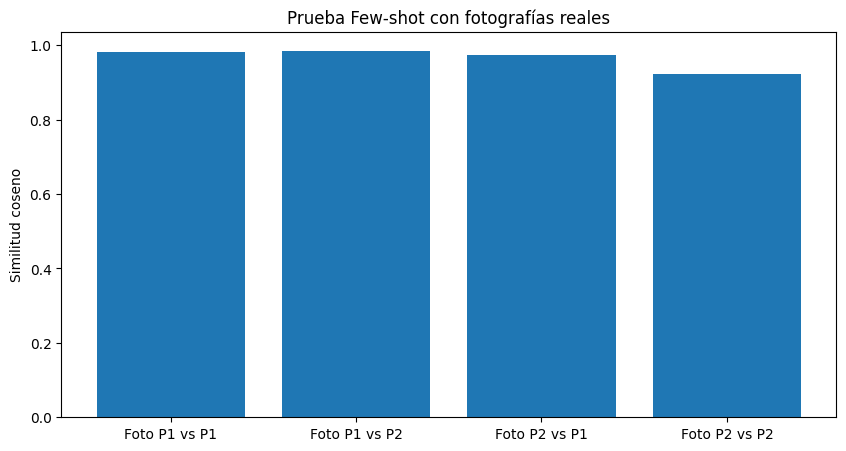

In [ ]:
# Creo una lista con los cuatro valores de similitud coseno.
# Incluyo las comparaciones de ambas fotografías con los dos prototipos.
valores = [
    sim_p1_p1,
    sim_p1_p2,
    sim_p2_p1,
    sim_p2_p2
]

# Defino los nombres que identificarán cada comparación.
nombres_grafica = [
    'Foto P1 vs P1',
    'Foto P1 vs P2',
    'Foto P2 vs P1',
    'Foto P2 vs P2'
]

# Creo una figura para representar los resultados.
plt.figure(figsize=(10, 5))

# Genero una gráfica de barras con las similitudes calculadas.
plt.bar(nombres_grafica, valores)

# Asigno el nombre al eje vertical.
plt.ylabel('Similitud coseno')

# Establezco el título de la gráfica.
plt.title('Prueba Few-shot con fotografías reales')

# Muestro la gráfica.
plt.show()

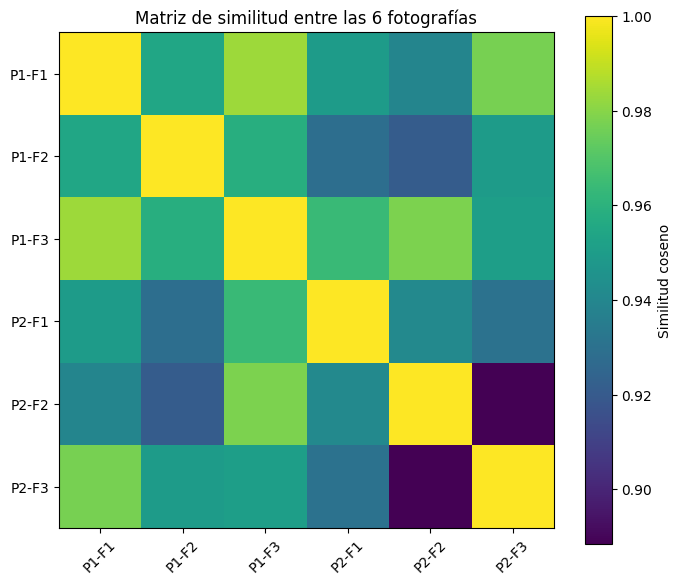

In [ ]:
# Calculo el producto matricial entre la matriz de embeddings
# y su transpuesta.
# Como los embeddings están normalizados, el producto punto
# representa la similitud coseno entre cada par de fotografías.
matriz = embeddings @ embeddings.T

# Desconecto la matriz del grafo computacional de PyTorch.
# Posteriormente la traslado a la CPU y la convierto en NumPy.
matriz_np = matriz.detach().cpu().numpy()

# Creo una figura para visualizar la matriz.
plt.figure(figsize=(7, 6))

# Represento la matriz como un mapa de calor.
plt.imshow(matriz_np)

# Agrego una barra de colores para interpretar los valores.
plt.colorbar(label='Similitud coseno')

# Defino las etiquetas correspondientes a las seis fotografías.
etiquetas = [
    'P1-F1', 'P1-F2', 'P1-F3',
    'P2-F1', 'P2-F2', 'P2-F3'
]

# Asigno las etiquetas al eje horizontal.
# rotation=45 permite mejorar su legibilidad.
plt.xticks(range(6), etiquetas, rotation=45)

# Asigno las etiquetas al eje vertical.
plt.yticks(range(6), etiquetas)

# Establezco el título de la matriz.
plt.title('Matriz de similitud entre las 6 fotografías')

# Ajusto automáticamente los espacios de la figura.
plt.tight_layout()

# Muestro la matriz de similitud.
plt.show()

In [ ]:
# EJEMPLO ALTERNATIVO

# Selecciono la segunda fotografía de la Persona 1 como Anchor.
anchor_alt = Xr[1]      # Persona 1 - Foto 2

# Selecciono la tercera fotografía de la Persona 1 como Positive.
positive_alt = Xr[2]    # Persona 1 - Foto 3

# Selecciono la segunda fotografía de la Persona 2 como Negative.
negative_alt = Xr[4]    # Persona 2 - Foto 2

# Desactivo el cálculo de gradientes porque solamente
# voy a realizar una evaluación de las fotografías.
with torch.no_grad():

    # Genero y normalizo el embedding del Anchor alternativo.
    # Agrego la dimensión del lote y traslado la imagen al dispositivo.
    ea = F.normalize(model(anchor_alt.unsqueeze(0).to(DEVICE)), p=2, dim=1)

    # Genero y normalizo el embedding del Positive alternativo.
    ep = F.normalize(model(positive_alt.unsqueeze(0).to(DEVICE)), p=2, dim=1)

    # Genero y normalizo el embedding del Negative alternativo.
    en = F.normalize(model(negative_alt.unsqueeze(0).to(DEVICE)), p=2, dim=1)

# Calculo la similitud coseno entre Anchor y Positive.
# Las dos imágenes pertenecen a la misma persona.
# Muestro el resultado con cuatro decimales.
print('Similitud A-P:', round(F.cosine_similarity(ea, ep).item(), 4))

# Calculo la similitud coseno entre Anchor y Negative.
# Las imágenes pertenecen a personas diferentes.
# Muestro el resultado con cuatro decimales.
print('Similitud A-N:', round(F.cosine_similarity(ea, en).item(), 4))

Similitud A-P: 0.9584
Similitud A-N: 0.921
